**Perception and Use of Artificial Intelligence in Dutch Labour Market Project**

**1st: Install libraries and explore the first dataset**

In [1]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Patch
import plotly.graph_objects as go
import seaborn as sns

In [2]:
#Loading the 1st data as dataframes & Inspect data
dataset_1 = 'Question 1 dataset.xlsx'
dataset_1= pd.read_excel(dataset_1, header = None)
dataset_1.shape


(7, 73)

In [3]:
dataset_1.columns

Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
       36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53,
       54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71,
       72],
      dtype='int64')

In [4]:
dataset_1

,0,1,2,3,4,5,6,7,8,9,...,63,64,65,66,67,68,69,70,71,72
0,4.1 Opvattingen over AI-toepassingen en de arb...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,"Verhogen van de productiviteit, doordat werk s...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ja,gasaansluitingnee_po,gasaansluitingnee_pb,Misschien,gasaansluiting_po,gasaansluiting_pb,Nee,gasaansluitingnee_po,gasaansluitingnee_pb,...,gasaansluitingnee_pb,Misschien,gasaansluiting_po,gasaansluiting_pb,Nee,gasaansluitingnee_po,gasaansluitingnee_pb,Weet niet,gasaansluitingnee_po,gasaansluitingnee_pb
3,NaN,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,...,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens
4,NaN,% van personen van 18 jaar of ouder,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Totaal,57,55.3,58.6,33.5,32,35,3.8,3.2,4.5,...,76.8,17.7,16.4,18.9,2.2,1.8,2.8,3.2,2.7,3.9


**Prepare the first dataset for visualization: Remove empty rows, reshape data, transform the format and translate from Dutch to English**

In [5]:
# Prepare dataset 1 for visualization

# Prepare data
data= dataset_1.iloc[6:].copy()

# Remove empty rows
data = data[data[0].notna()]

# Get question names
question_row = dataset_1.iloc[1,1:]
questions = (
    question_row
    .dropna()
    .unique()
)

# Define response labels
responses = [
     "Ja",
    "Misschien",
    "Nee",
    "Weet niet"
]

# Reshape the data
all_rows = []

for q, question in enumerate(questions):

    # Each question has 12 columns
    start_col = 1 + q * 12

    for r, response in enumerate(responses):

        # Each response has 3 columns:
        # Estimate, Lower CI, Upper CI
        start = start_col + r * 3

        temp = pd.DataFrame({
            "question_nl": question,
            "response_nl": response,
            "estimate": data[start]
        }) # Keep only columns needed for visualization
        all_rows.append(temp)

# Combine all questions and responses
tidy_dataset_1 = pd.concat(
    all_rows,
    ignore_index=True
    )

# Translation dictionaries

# Translate response labels
response_translation = {
    "Ja": "Yes",
    "Misschien": "Maybe",
    "Nee": "No",
    "Weet niet": "Do not know"
}

# Translate questions
question_translation = {
    "Verhogen van de productiviteit, doordat werk sneller uitgevoerd kan worden":
        "Increasing productivity, as work can be carried out faster.",

    "Oplossen van het personeelstekort om bepaalde sectoren, doordat er minder personeel nodig is":
        "Solving the workforce shortage for certain sectors, as less personnel are needed.",

    "Overnemen van onveilige banen":
        "Taking over unsafe jobs.",

    "Bepaalde werkzaamheden worden minder interessant":
        "Certain tasks are becoming less interesting.",

    "Verlies van belangrijke kennis en vaardigheden van personeel":
        "Loss of important staff knowledge and skills.",

    "Verdwijnen van bepaalde banen":
        "Disappearance of certain jobs."
}

# Replace Dutch columns
tidy_dataset_1["question_en"] = tidy_dataset_1["question_nl"].replace(question_translation)
tidy_dataset_1["response_en"] = tidy_dataset_1["response_nl"].replace(response_translation)

# Reorder columns
tidy_dataset_1 = tidy_dataset_1[["question_en", "response_en", "estimate"]]

# Save cleaned dataset
tidy_dataset_1.to_csv(
    "clean_dataset1.csv",
    index=False
)
# Print
tidy_dataset_1

,question_en,response_en,estimate
0,"Increasing productivity, as work can be carrie...",Yes,57
1,"Increasing productivity, as work can be carrie...",Maybe,33.5
2,"Increasing productivity, as work can be carrie...",No,3.8
3,"Increasing productivity, as work can be carrie...",Do not know,4.2
4,Solving the workforce shortage for certain sec...,Yes,46.2
5,Solving the workforce shortage for certain sec...,Maybe,36.4
6,Solving the workforce shortage for certain sec...,No,11.4
7,Solving the workforce shortage for certain sec...,Do not know,4.5
8,Taking over unsafe jobs.,Yes,40.7
9,Taking over unsafe jobs.,Maybe,37.4


**Steps to visualize the number of responses for each statement: Remove "Do not know" responses, define question order, devide them into 2 categories, pivot data & create the chart (bars, axes, labels, titles, legend, source)**

/tmp/ipykernel_610/926836726.py:27: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  plot_data = df1.pivot_table(


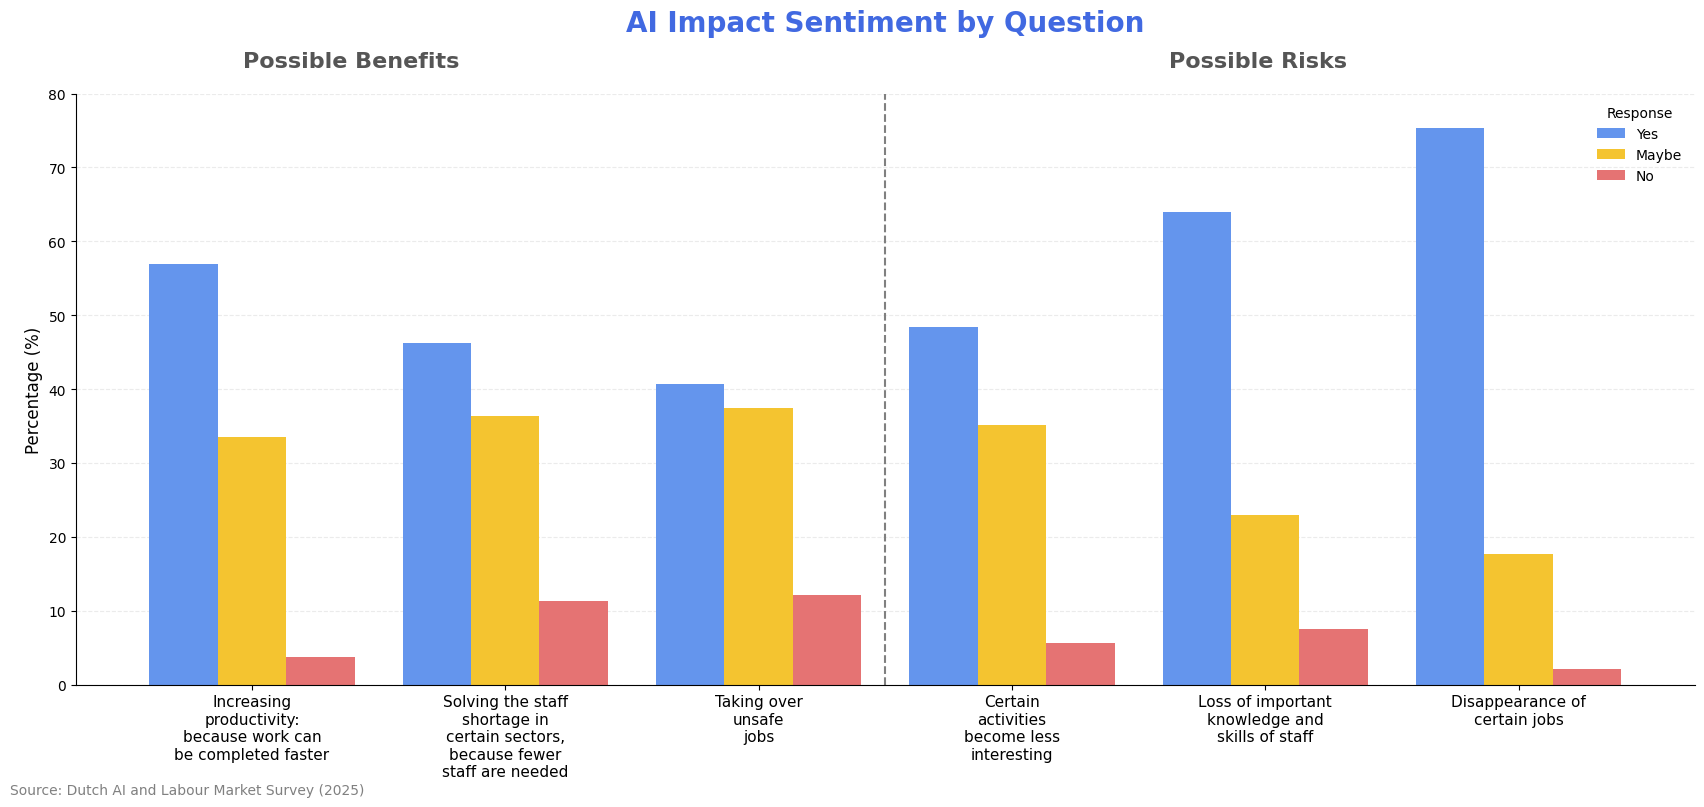

In [6]:
# 1st Visualization

# Load cleaned dataset
df1 = pd.read_csv("clean_dataset1.csv")

# Remove "Do not know" answer for the purpose of the visualization
df1 = df1[df1["response_en"] != "Do not know"]

# Define question order
question_order = [
    "Increasing productivity, as work can be carried out faster.",
    "Solving the workforce shortage for certain sectors, as less personnel are needed.",
    "Taking over unsafe jobs.",
    "Certain tasks are becoming less interesting.",
    "Loss of important staff knowledge and skills.",
    "Disappearance of certain jobs."
]

# Make question order categorical
df1["question_en"] = pd.Categorical(
    df1["question_en"],
    categories=question_order,
    ordered=True
)

# Pivot data for plotting
plot_data = df1.pivot_table(
    index="question_en",
    columns="response_en",
    values="estimate"
)

# Make sure responses appear in the desired order
plot_data = plot_data[["Yes", "Maybe", "No"]]


# Create the chart
fig, ax = plt.subplots(figsize=(17, 8))

x = np.arange(len(plot_data))

# Width of each bar
width = 0.27

# Create grouped bars
ax.bar(
    x - width,
    plot_data["Yes"],
    width,
    label="Yes",
    color= "cornflowerblue"
)

ax.bar(
    x,
    plot_data["Maybe"],
    width,
    label="Maybe",
    color="#F4C430"
)

ax.bar(
    x + width,
    plot_data["No"],
    width,
    label="No",
    color="#E57373"
)

# 6. Create axis and labels
ax.set_ylabel(
    "Percentage (%)",
    fontsize=12
)

ax.set_xticks(x)

ax.set_xticklabels(
    [
        "Increasing\nproductivity:\nbecause work can\nbe completed faster",
        "Solving the staff\nshortage in\ncertain sectors,\nbecause fewer\nstaff are needed",
        "Taking over\nunsafe\njobs",
        "Certain\nactivities\nbecome less\ninteresting",
        "Loss of important\nknowledge and\nskills of staff",
        "Disappearance of\ncertain jobs"
    ],
    fontsize=11
)

ax.set_ylim(0, 80)

# Title
ax.set_title(
    "AI Impact Sentiment by Question",
    fontsize=20,
    fontweight="bold",
    pad=45,
    color="#4169E1"
)

# Benefit & Risk categories
ax.text(
    0.17,
    1.045,
    "Possible Benefits",
    transform=ax.transAxes,
    ha="center",
    fontsize=16,
    fontweight="bold",
    color= "#555555"
)

ax.text(
    0.73,
    1.045,
    "Possible Risks",
    transform=ax.transAxes,
    ha="center",
    fontsize=16,
    fontweight="bold",
    color= "#555555"
)

# Separator between Benefits and Risks
ax.axvline(
    x=2.5,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

# Grid
ax.yaxis.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Clean up spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Source
fig.text(
    0.0001,
    0.0001,
    "Source: Dutch AI and Labour Market Survey (2025)",
    fontsize=10,
    color="gray"
)

# Final layout
ax.legend(
    title="Response",
    loc="upper right",
    frameon=False
)

plt.tight_layout()

plt.show()

**Create the 2nd visualization of the 1st dataset: pivot table,reverse code negative questions, combine reponses from "Do not know" and "Maybe" into one category, calculate total answers, covert them to proportion, and create the chart as a semi-donut.**

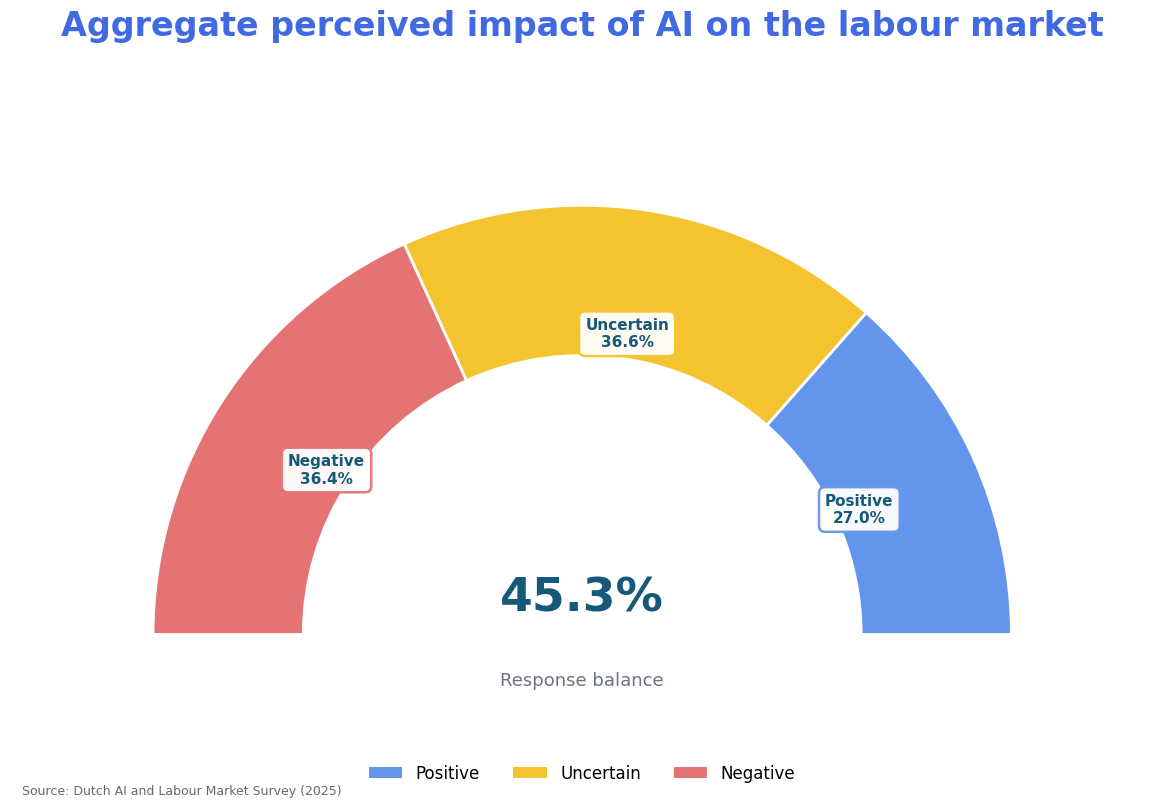

In [7]:
# 2nd visualization

# Load cleaned dataset
df2 = pd.read_csv("clean_dataset1.csv")

# Pivot table
df2 = df2.pivot(
    index="question_en",
    columns="response_en",
    values="estimate"
)

# 1. Negative question adjustment

risks = [
    "Certain tasks are becoming less interesting.",
    "Loss of important staff knowledge and skills.",
    "Disappearance of certain jobs."
]

risk_mask = df2.index.isin(risks)

df2.loc[risk_mask, ["Yes", "No"]] = (
    df2.loc[risk_mask, ["No", "Yes"]].values
)

# 2. Aggregate across questions

# Combine "Do not know answer" with "Maybe"
df2["Maybe"] = (df2["Maybe"] + df2["Do not know"] )

# Now calculate totals AFTER combining
yes_total = df2["Yes"].sum()
maybe_total = df2["Maybe"].sum()
no_total = df2["No"].sum()

total = yes_total + maybe_total + no_total

# Convert to proportions
yes_pct = yes_total / total
maybe_pct = maybe_total / total
no_pct = no_total / total

# Calculate overall balance
score = (
    yes_pct * 1.0 +
    maybe_pct * 0.5 +
    no_pct * 0.0
)

"Positive:", round(yes_pct * 100, 1)
"Uncertain:", round(maybe_pct * 100, 1)
"Negative:", round(no_pct * 100, 1)
"Overall balance:", round(score * 100, 1)

# 4. Colors

colors = {
    "Positive": "cornflowerblue",
    "Uncertain": "#F4C430",
    "Negative": "#E57373"
}

# 5. Semi-donut segments

segments = [
    ("Negative", no_pct * 180),
    ("Uncertain", maybe_pct * 180),
    ("Positive", yes_pct * 180)
]

# 6. Create figure

fig, ax = plt.subplots(figsize=(14, 8))

start_angle = 180
radius = 1.2
width = 0.42

current_angle = start_angle

# 7. Draw semi-donut + labels

for label, angle in segments:

    theta1 = current_angle - angle
    theta2 = current_angle

    # Draw segment
    wedge = Wedge(
        center=(0, 0),
        r=radius,
        theta1=theta1,
        theta2=theta2,
        width=width,
        facecolor=colors[label],
        edgecolor="white",
        linewidth=2
    )

    ax.add_patch(wedge)

    # Label position

    mid_angle = (theta1 + theta2) / 2

    text_radius = 0.85

    x_text = (
        text_radius *
        np.cos(np.radians(mid_angle))
    )

    y_text = (
        text_radius *
        np.sin(np.radians(mid_angle))
    )

    pct_value = {
        "Positive": yes_pct,
        "Uncertain": maybe_pct,
        "Negative": no_pct
    }[label]

    ax.text(
        x_text,
        y_text,
        f"{label}\n{pct_value * 100:.1f}%",
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="center",
        color="#155978",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor=colors[label],
            linewidth=1.8,
            alpha=0.95
        )
    )

    # Move to next segment
    current_angle = theta1

# 8. Center score

ax.text(
    0,
    0.10,
    f"{score * 100:.1f}%",
    fontsize=34,
    fontweight="bold",
    ha="center",
    va="center",
    color="#155978"
)

ax.text(
    0,
    -0.13,
    "Response balance",
    fontsize=13,
    ha="center",
    va="center",
    color="#6B7280"
)

# 9. Legend

legend_elements = [
    Patch(
        facecolor=colors["Positive"],
        label="Positive"
    ),
    Patch(
        facecolor=colors["Uncertain"],
        label="Uncertain"
    ),
    Patch(
        facecolor=colors["Negative"],
        label="Negative"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    fontsize=12,
    frameon=False
)

# 10. Layout

ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-0.2, 1.5)

ax.set_aspect("equal")
ax.axis("off")

# 11. Title

plt.title(
    "Aggregate perceived impact of AI on the labour market",
    fontsize=24,
    fontweight="bold",
    pad=45,
    color="#4169E1"
)

# 12. Source

fig.text(
    0.1,
    0.01,
    "Source: Dutch AI and Labour Market Survey (2025)",
    fontsize=9,
    color="dimgray",
    ha="left"
)

# 13. Final layout

plt.tight_layout()

plt.subplots_adjust(
    top=0.88,
    bottom=0.12
)

plt.show()

**Explore dataset 2**

In [8]:
dataset_2 = 'Question 2 dataset.xlsx'
dataset_2= pd.read_excel(dataset_2, header = None)
dataset_2

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,4.12 Opvattingen over AI-toepassingen en de ar...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Huidig gebruik van AI voor eigen werk,NaN,NaN,NaN,NaN,NaN,Verwachting dat AI in de komende 10 jaar (meer...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ja,gasaansluitingnee_po,gasaansluitingnee_pb,Nee,gasaansluitingnee_po,gasaansluitingnee_pb,Ja,gasaansluitingnee_po,gasaansluitingnee_pb,Nee,NaN,NaN,Weet niet,gasaansluitingnee_po,gasaansluitingnee_pb
3,NaN,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens
4,NaN,% van personen van 18 jaar of ouder,NaN,NaN,NaN,NaN,NaN,% van personen van 18 jaar of ouder met betaal...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Totaal,42.9,40.9,45,57.1,55,59.1,69.6,67.7,71.4,15,13.6,16.6,15.4,13.9,16.9
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Geslacht,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Mannen,45.9,43.1,48.7,54.1,51.3,56.9,71.1,68.4,73.6,15.2,13.2,17.4,13.7,11.9,15.8


**Perform data cleaning and transformation: transform the dataset format, classify observations by demographic section, forward-filled group labels, standardize categorical variables, and translate Dutch labels.**

In [9]:
#transform the format of dataset 2
#Question definition
Question= {
    'Current AI use':{
        'question col start': 1,
        'Response': {
            'Yes': [1],
            'No': [4]
        }
    },

    'Future AI expectation': {
        'question col start': 7,
        'Response': {
            'Yes': [7],
            'No': [10],
            'Do not know': [13]
        }
    }
}
#Demographic section
section_labels = [
    'Totaal',
    'Geslacht',
    'Leeftijd',
    'Onderwijsniveau',
    'Herkomst',
    'Financiële welvaart'
]
#Data starts at row 6
data = dataset_2.iloc[6:].copy()
#Rename first column
data= data.rename(columns={0: 'group'})
#Demographic type column
data['demographic_type']= np.where(
    data["group"].isin(section_labels),
    data["group"],
    np.nan
)
#Forward fill section labels
data["demographic_type"] = data["demographic_type"].ffill()

# Remove section header rows
data = data[
    ~data["group"].isin(section_labels)
]
# Remove empty rows
data = data[
    data["group"].notna()
]
#Build dataset
all_rows = []

for question_name, qinfo in Question.items():

    for response_name, cols in qinfo["Response"].items():

        temp = pd.DataFrame({
            "question": question_name,
            "demographic_type": data["demographic_type"],
            "demographic_group": data["group"],
            "response": response_name,
            "estimate": data[cols[0]],
        })

        all_rows.append(temp)

# Combine everything
tidy_dataset2 = pd.concat(all_rows)

# Reset index
tidy_dataset2 = tidy_dataset2.reset_index(drop=True)

# Translate Dutch
tidy_dataset2["demographic_type"] = tidy_dataset2["demographic_type"].replace({
    "Geslacht": "Gender",
    "Leeftijd": "Age",
    "Onderwijsniveau": "Education",
    "Herkomst": "Origin",
    "Financiële welvaart": "Financial welfare"
})

tidy_dataset2["demographic_group"] = tidy_dataset2["demographic_group"].replace({
    "Totaal": "Total",
    "Mannen": "Men",
    "Vrouwen": "Women",
    "18 tot 25 jaar": "18-25 years old",
    "25 tot 45 jaar": "25-45 years old",
    "45 tot 65 jaar": "45-65 years old",
    "65 jaar of ouder": "65+ years old",
    "Basisonderwijs, vmbo, mbo1": "Primary education, vmbo, mbo1",
    "Nederlandse herkomst": "Dutch origin",
    "Geboren in Nederland, ouder(s) in het buitenland": "Born in the Netherlands, parent(s) abroad",
    "Geboren in het buitenland": "Born abroad",
    "1e 20%-groep (laagst)": "1st 20% group (lowest)",
    "2e 20%-groep": "2nd 20% group",
    "3e 20%-groep": "3rd 20% group",
    "4e 20%-groep": "4th 20% group",
    "5e 20%-groep (hoogst)": "5th 20% group (highest)"
})

# Save clean dataset
tidy_dataset2.to_csv(
    "clean_dataset2.csv",
    index=False
)
tidy_dataset2


,question,demographic_type,demographic_group,response,estimate
0,Current AI use,Gender,Men,Yes,45.9
1,Current AI use,Gender,Women,Yes,39.6
2,Current AI use,Age,18-25 years old,Yes,34.6
3,Current AI use,Age,25-45 years old,Yes,51.3
4,Current AI use,Age,45-65 years old,Yes,39.8
...,...,...,...,...,...
80,Future AI expectation,Financial welfare,1st 20% group (lowest),Do not know,18.3
81,Future AI expectation,Financial welfare,2nd 20% group,Do not know,20
82,Future AI expectation,Financial welfare,3rd 20% group,Do not know,17.2
83,Future AI expectation,Financial welfare,4th 20% group,Do not know,14.3


**Create a custom interactive chart: create custom chart elements, calculate adoption gaps and visualize differences between demographic groups using Plotly.**

In [10]:
# PREPARE DATA

#Dumbbell chart

df3 = tidy_dataset2[
    tidy_dataset2["response"] == "Yes"
].copy()

df3 = df3.pivot_table(
    index=["demographic_type", "demographic_group"],
    columns="question",
    values="estimate"
).reset_index()

df3["Gap"] = (
    df3["Future AI expectation"]
    - df3["Current AI use"]
)

# SECTION ORDER

groups = {

    "GENDER": [
        "Men",
        "Women"
    ],

    "AGE GROUP": [
        "18-25 years old",
        "25-45 years old",
        "45-65 years old",
        "65+ years old"
    ],

    "EDUCATION LEVEL": [
        "Primary education, vmbo, mbo1",
        "Havo, vwo, mbo2-4",
        "Hbo, wo"
    ],

    "ORIGIN GROUP": [
        "Dutch origin",
        "Born in the Netherlands, parent(s) abroad",
        "Born abroad"
    ],

    "HOUSEHOLD INCOME": [
        "1st 20% group (lowest)",
        "2nd 20% group",
        "3rd 20% group",
        "4th 20% group",
        "5th 20% group (highest)"
    ]
}

section_headers = {
    "GENDER": "1. GENDER",
    "AGE GROUP": "2. AGE GROUP",
    "EDUCATION LEVEL": "3. EDUCATION LEVEL",
    "ORIGIN GROUP": "4. ORIGIN GROUP",
    "HOUSEHOLD INCOME": "5. HOUSEHOLD INCOME"
}

# BUILD PLOT DATA

rows = []

for section, members in groups.items():

    # Header row
    rows.append({
        "demographic_group": section,
        "Current AI use": None,
        "Future AI expectation": None,
        "Gap": None,
        "header": True
    })

    for member in members:

        subset = df3[
            df3["demographic_group"] == member
        ]

        if subset.empty:
            continue

        row = subset.iloc[0]

        rows.append({
            "demographic_group": member,
            "Current AI use": row["Current AI use"],
            "Future AI expectation": row["Future AI expectation"],
            "Gap": row["Gap"],
            "header": False
        })

plot_df = pd.DataFrame(rows)

# FIGURE

fig = go.Figure()

# SECTION COLORS

section_fill = {
    "GENDER": "rgba(190,220,255,0.45)",                    # blue
    "AGE GROUP": "rgba(205,240,205,0.45)",                # green
    "EDUCATION LEVEL": "rgba(225,210,255,0.45)",          # purple
    "ORIGIN GROUP": "rgba(255,245,180,0.45)",             # yellow
    "HOUSEHOLD INCOME": "rgba(255,210,230,0.45)"          # pink
}

# SECTION SHADING

current_section = None
section_start = None

for i, row in plot_df.iterrows():

    if row["header"]:

        if current_section is not None:

            fig.add_hrect(
                y0=section_start + 0.5,
                y1=i - 0.5,
                fillcolor=section_fill[current_section],
                opacity=0.6,
                line_width=0,
                layer="below"
            )

        current_section = row["demographic_group"]
        section_start = i

# last section

fig.add_hrect(
    y0=section_start + 0.5,
    y1=len(plot_df) - 0.5,
    fillcolor=section_fill[current_section],
    opacity=0.6,
    line_width=0,
    layer="below"
)

# LINES + GAP LABELS + HEADERS

for i, row in plot_df.iterrows():

    # SECTION HEADER

    if row["header"]:

        fig.add_annotation(

            xref="paper",
            yref="y",

            x=-0.14,
            y=i,

            text=f"<b>{section_headers[row['demographic_group']]}</b>",

            showarrow=False,

            xanchor="left",

            align="left",

            font=dict(
                size=16,
                color="#4169E1"
            )
        )

        continue

    # DUMBBELL LINE

    fig.add_shape(
        type="line",
        x0=row["Current AI use"],
        x1=row["Future AI expectation"],
        y0=i,
        y1=i,
        line=dict(
            color="green",
            width=3
        )
    )

    # GAP LABEL

    fig.add_annotation(
        x=(
            row["Current AI use"]
            + row["Future AI expectation"]
        ) / 2,

        y=i,

        text=f"+{row['Gap']:.0f}%",

        showarrow=False,

        bgcolor="white",

        font=dict(
            size=10
        )
    )

# DATA ROWS ONLY

data_rows = plot_df[
    ~plot_df["header"]
]

# CURRENT POINTS

fig.add_trace(
    go.Scatter(
        x=data_rows["Current AI use"],
        y=data_rows.index,

        mode="markers",

        marker=dict(
            color="#F4C430",
            size=11
        ),

        name="Current AI Use",

        text=data_rows["demographic_group"],

        hovertemplate=
        "<b>%{text}</b><br>" +
        "Current AI Use: %{x:.0f}%<extra></extra>"
    )
)

# FUTURE POINTS

fig.add_trace(
    go.Scatter(
        x=data_rows["Future AI expectation"],
        y=data_rows.index,

        mode="markers",

        marker=dict(
            color="cornflowerblue",
            size=11
        ),

        name="Future AI Use Expectation",

        text=data_rows["demographic_group"],

        hovertemplate=
        "<b>%{text}</b><br>" +
        "Future AI Use: %{x:.0f}%<extra></extra>"
    )
)

# Y AXIS LABELS

ticktext = []

for _, row in plot_df.iterrows():

    if row["header"]:
        ticktext.append("")
    else:
        ticktext.append(
            row["demographic_group"]
        )

# LAYOUT

fig.update_layout(

    title=dict(
        text="<b>THE AI ADOPTION GAP: Current Use (2025) vs Future Expectation (Next 10 Years)</b>",
        x=0.5,
        font=dict(
            size=18,
            color="#4169E1"
        )
    ),

    xaxis=dict(
        title="Percentage of the population 18 years old and above (%)",
        range=[0, 100],
        showgrid=True,
        gridcolor="lightgray"
    ),

    yaxis=dict(
        tickmode="array",
        tickvals=list(plot_df.index),
        ticktext=ticktext,
        autorange="reversed"
    ),

    plot_bgcolor="white",
    paper_bgcolor="white",

    width=1400,
    height=1000,

    hovermode="closest",

    legend=dict(
        orientation="h",
        y=1.05,
        x=0.72,
        font=dict(size=12)
    ),

    margin=dict(
        l=260,
        r=80,
        t=90,
        b=80
    )
)

fig.show()

**Inspect the third dataset**

In [12]:
#Loading the 3rd dataset as dataframe & Inspect data
dataset3 = 'different AI technologies.csv'
dataset3= pd.read_csv(dataset3)
dataset3.shape

(6, 15)

In [13]:
dataset3.columns

Index(['Jaar',
       'Use of specific AI technologies, Machine learning (Use of AI technology (%))',
       'Use of specific AI technologies, Machine learning (95% confidence interval) (Use of AI technology (%))',
       'Use of specifiec AI technologies, Image recognition (Use of AI technology (%))',
       'Use of specific AI technologies, Afbeeldingherkenning (95% confidence interval) (Use of AI technology (%))',
       'Use of specific AI technologies, Robots autonomous vehicles (Use of AI technology (%))',
       'Use of specific AI technologies, Robots autonomous vehicles (95% confidence interval) (Use of AI technology (%))',
       'Use of specific AI technologies, Robots process automation (Use of AI technology (%))',
       'Use of specific AI technologies, Robots process automation (95% confidence interval) (Use of AI technology (%))',
       'Use of specific AI technologies, Speech recognition (Use of AI technology (%))',
       'Use of specific AI technologies, Speech reco

In [14]:
dataset3

,Jaar,"Use of specific AI technologies, Machine learning (Use of AI technology (%))","Use of specific AI technologies, Machine learning (95% confidence interval) (Use of AI technology (%))","Use of specifiec AI technologies, Image recognition (Use of AI technology (%))","Use of specific AI technologies, Afbeeldingherkenning (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Robots autonomous vehicles (Use of AI technology (%))","Use of specific AI technologies, Robots autonomous vehicles (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Robots process automation (Use of AI technology (%))","Use of specific AI technologies, Robots process automation (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Speech recognition (Use of AI technology (%))","Use of specific AI technologies, Speech recognition (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Text mining (Use of AI technology (%))","Use of specific AI technologies, Text mining (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Natural language generation (Use of AI technology (%))","Use of specific AI technologies, Natural language generation (95% confidence interval) (Use of AI technology (%))"
0,2020,5.6,5.2 - 6.2,NaN,-,1.6,1.4 - 1.9,4.2,3.8 - 4.6,3.1,2.7 - 3.5,NaN,NaN,NaN,NaN
1,2021,5.8,5.3 - 6.3,3.7,3.3 - 4.1,2.1,1.8 - 2.4,6.3,5.8 - 6.9,3.1,2.7 - 3.5,3.9,3.5 - 4.4,2.2,1.9 - 2.5
2,2022*,7.2,6.6 - 7.8,4.3,3.9 - 4.7,2.5,2.2 - 2.9,8.3,7.7 - 9,3.7,3.3 - 4.2,5.3,4.8 - 5.9,2.7,2.4 - 3.1
3,2023*,5.6,5.1 - 6.1,3.7,3.3 - 4.1,2.2,2 - 2.6,5.6,5.1 - 6.1,3.7,3.3 - 4.2,5.3,4.8 - 5.8,4.2,3.8 - 4.7
4,2024*,6.3,5.8 - 6.8,4.5,4.1 - 5,2.0,1.8 - 2.3,6.0,5.6 - 6.5,6.5,6 - 7,13.5,12.7 - 14.4,12.3,11.5 - 13.1
5,* provisional figures,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Perform data selection and transformation**

In [15]:
# Check index of columns
for i, col in enumerate(dataset3.columns):
    print(i, col)
# Create a new dataset for plot 4 only with columns with estimated values
df4= dataset3.iloc[: 5, [0, 1, 3, 5, 7, 9, 11, 13]]
# Rename columns
df4.columns = ['Year', 'Machine Learning', 'Image Recognition', 'Robots autonomous vehicles', 'Robots process automation', 'Speech recognition', 'Text mining', 'Natural language generation']
df4

0 Jaar
1 Use of specific AI technologies, Machine learning (Use of AI technology (%))
2 Use of specific AI technologies, Machine learning (95% confidence interval) (Use of AI technology (%))
3 Use of specifiec AI technologies, Image recognition (Use of AI technology (%))
4 Use of specific AI technologies, Afbeeldingherkenning (95% confidence interval) (Use of AI technology (%))
5 Use of specific AI technologies, Robots autonomous vehicles (Use of AI technology (%))
6 Use of specific AI technologies, Robots autonomous vehicles (95% confidence interval) (Use of AI technology (%))
7 Use of specific AI technologies, Robots process automation (Use of AI technology (%))
8 Use of specific AI technologies, Robots process automation (95% confidence interval) (Use of AI technology (%))
9 Use of specific AI technologies, Speech recognition (Use of AI technology (%))
10 Use of specific AI technologies, Speech recognition (95% confidence interval) (Use of AI technology (%))
11 Use of specific AI te

,Year,Machine Learning,Image Recognition,Robots autonomous vehicles,Robots process automation,Speech recognition,Text mining,Natural language generation
0,2020,5.6,NaN,1.6,4.2,3.1,NaN,NaN
1,2021,5.8,3.7,2.1,6.3,3.1,3.9,2.2
2,2022*,7.2,4.3,2.5,8.3,3.7,5.3,2.7
3,2023*,5.6,3.7,2.2,5.6,3.7,5.3,4.2
4,2024*,6.3,4.5,2.0,6.0,6.5,13.5,12.3


**Create the 4th graph: set up the plot basics and plot each line, add marker for each year.**

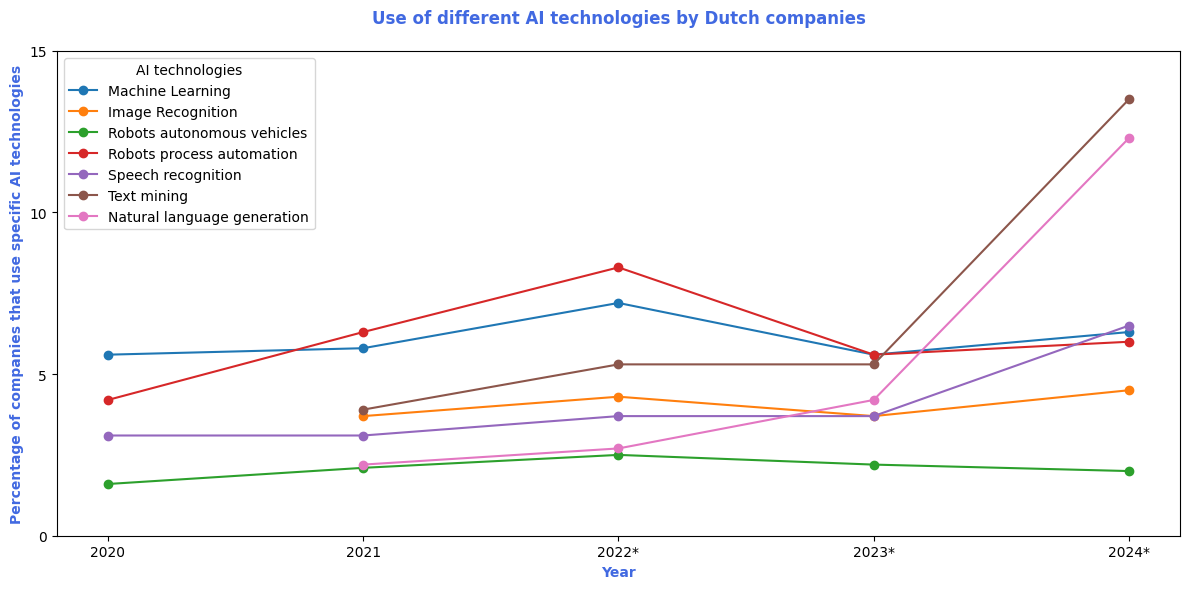

In [16]:
# Set up the plot
plt.figure(figsize=(12, 6))
plt.ylim(0, 15)
plt.yticks(range(0, 16, 5))
plt.xlabel('Year', fontweight='bold',color="#4169E1")
plt.ylabel('Percentage of companies that use specific AI technologies', fontweight='bold', color="#4169E1")
plt.title('Use of different AI technologies by Dutch companies', fontweight='bold', pad=20, color="#4169E1")

# Define x-axis values
x = df4['Year']

# Plot each AI technology
plt.plot(x, df4["Machine Learning"], label="Machine Learning", marker = 'o')
plt.plot(x, df4["Image Recognition"], label="Image Recognition", marker = 'o')
plt.plot(x, df4["Robots autonomous vehicles"], label="Robots autonomous vehicles", marker = 'o')
plt.plot(x, df4["Robots process automation"], label="Robots process automation", marker = 'o')
plt.plot(x, df4["Speech recognition"], label="Speech recognition", marker = 'o')
plt.plot(x, df4["Text mining"], label="Text mining", marker = 'o')
plt.plot(x, df4["Natural language generation"], label="Natural language generation", marker = 'o')

plt.legend(title="AI technologies")
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

**Inspect the fourth dataset**

In [17]:
#Loading the 4th dataset as dataframe & Inspect data
dataset_4 = 'number of companies - timeline.csv'
dataset_4= pd.read_csv(dataset_4)
dataset_4.shape

(6, 5)

In [18]:
dataset_4.columns

Index(['Year', '7 technologies (Use of AI technology (%))',
       '7 technologies (95% confidence interval) (Use of AI technology (%))',
       '4 technologies (Use of AI technology (%))',
       '4 technologies (95% confidence interval) (Use of AI technology (%))'],
      dtype='object')

In [19]:
dataset_4

,Year,7 technologies (Use of AI technology (%)),7 technologies (95% confidence interval) (Use of AI technology (%)),4 technologies (Use of AI technology (%)),4 technologies (95% confidence interval) (Use of AI technology (%))
0,2020,NaN,NaN,9.9,9.3 - 10.6
1,2021,13.1,12.3 - 13.9,10.7,10 - 11.4
2,2022*,15.8,14.9 - 16.7,13.3,12.6 - 14.1
3,2023*,14.0,13.2 - 14.8,10.6,9.9 - 11.3
4,2024*,22.7,21.7 - 23.8,12.9,12.2 - 13.6
5,* provisional figures,NaN,NaN,NaN,NaN


**Select specific rows and columns to visualize the chart**

In [20]:
df5 = dataset_4.iloc[:5, [0, 1, 3]]
df5

,Year,7 technologies (Use of AI technology (%)),4 technologies (Use of AI technology (%))
0,2020,NaN,9.9
1,2021,13.1,10.7
2,2022*,15.8,13.3
3,2023*,14.0,10.6
4,2024*,22.7,12.9


**Merge the two datasets together on year**

In [21]:
# Merge df4 and df5 together
merged_df = pd.merge(df4, df5, on='Year')
merged_df

,Year,Machine Learning,Image Recognition,Robots autonomous vehicles,Robots process automation,Speech recognition,Text mining,Natural language generation,7 technologies (Use of AI technology (%)),4 technologies (Use of AI technology (%))
0,2020,5.6,NaN,1.6,4.2,3.1,NaN,NaN,NaN,9.9
1,2021,5.8,3.7,2.1,6.3,3.1,3.9,2.2,13.1,10.7
2,2022*,7.2,4.3,2.5,8.3,3.7,5.3,2.7,15.8,13.3
3,2023*,5.6,3.7,2.2,5.6,3.7,5.3,4.2,14.0,10.6
4,2024*,6.3,4.5,2.0,6.0,6.5,13.5,12.3,22.7,12.9


**Create a custom infographic: extract specific years, convert values to numeric, sort technologies by adoption, create custom circles, add branches and annotations to create a custom comparison between 2020 and 2024.**

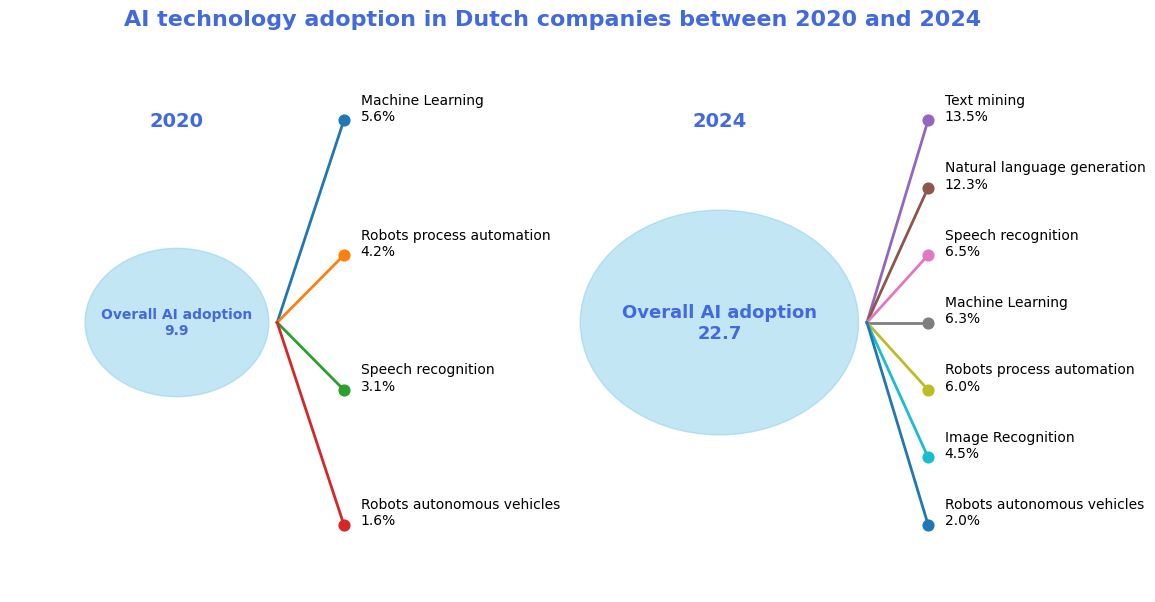

In [22]:
# Plot - Tree chart
# Set up the plot
fig, ax = plt.subplots(figsize=(14,7))

# AI adoption values
overall_2020 = merged_df[merged_df['Year'] == '2020']['4 technologies (Use of AI technology (%))'].iloc[0]
overall_2024 = merged_df[merged_df['Year'] == '2024*']['7 technologies (Use of AI technology (%))'].iloc[0]
value_2020 = merged_df[merged_df['Year'] == '2020'].iloc[0, 1:8].dropna().apply(pd.to_numeric, errors='coerce')
value_2024 = merged_df[merged_df['Year'] == '2024*'].iloc[0, 1:8].dropna().apply(pd.to_numeric, errors='coerce')

# Sort descending
value_2020 = value_2020.sort_values(ascending=False)
value_2024 = value_2024.sort_values(ascending=False)

# Scale circle radius
r2020 = np.sqrt(overall_2020) * 0.35
r2024 = np.sqrt(overall_2024) * 0.35

# Draw circles
circle1 = plt.Circle((2,5), r2020, alpha=0.5, color = 'skyblue')
circle2 = plt.Circle((8.5,5), r2024, alpha=0.5, color = 'skyblue')

ax.add_patch(circle1)
ax.add_patch(circle2)

# Labels
ax.text(2,5,
        f'Overall AI adoption\n{overall_2020}',
        ha='center',
        va='center',
        fontsize=10,
        weight='bold',
        color="#4169E1")

ax.text(2,8,
        '2020',
        ha='center',
        va='center',
        fontsize=14,
        weight='bold',
        color="#4169E1")

ax.text(8.5,5,
        f'Overall AI adoption\n{overall_2024}',
        ha='center',
        va='center',
        fontsize=13,
        weight='bold',
        color="#4169E1")

ax.text(8.5,8,
        '2024',
        ha='center',
        va='center',
        fontsize=14,
        weight='bold',
        color="#4169E1")


# Technology branches
tech_2020 = [
    (f"{tech}\n{value}%", y)
    for y, (tech, value) in zip(
       range(8, 8-(len(value_2020)*2), -2),
        value_2020.items()
    )
]

for label, y in tech_2020:
    ax.plot([2+r2020+0.1,4], [5,y], linewidth=2)
    ax.scatter(4,y, s=60)
    ax.text(4.2, y, label)


tech_2024 = [
    (f"{tech}\n{value}%", y)
    for y, (tech, value) in zip(
        range(8, 8-len(value_2024), -1),
        value_2024.items()
    )
]

for label, y in tech_2024:
    ax.plot([8.5+r2024+0.1,11], [5,y], linewidth=2)
    ax.scatter(11,y, s=60)
    ax.text(11.2, y, label)

# Arrow
ax.set_xlim(0,13)
ax.set_ylim(1,9)

ax.set_title('AI technology adoption in Dutch companies between 2020 and 2024',
             fontsize=16,
             fontweight='bold',
             pad=20,
             color="#4169E1"
             )
ax.axis ('off')

plt.show()